<a href="https://colab.research.google.com/github/SabaFeizi/Machine-Learning-Fall2026/blob/main/Linear_Regression_Ames_House_Prices_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# 🏠 قیمت این خانه چند است؟
### حل یک مسئله‌ی واقعی با رگرسیون خطی — از دادهٔ خام تا مدل نهایی

فرض کنید تازه در یک بنگاه املاک در شهر **Ames** (ایالت آیووا، آمریکا) استخدام شده‌اید.
مدیرتان یک فایل اکسل از فروش‌های چند سال اخیر به شما می‌دهد و می‌پرسد:

> «می‌توانی برنامه‌ای بنویسی که با دیدن مشخصات یک خانه، قیمتش را حدس بزند؟»

در این نوت‌بوک قدم‌به‌قدم همین کار را انجام می‌دهیم:

| قدم | چه کار می‌کنیم؟ | ابزار اصلی |
|---|---|---|
| ۱ | با داده آشنا می‌شویم و چند دادهٔ عجیب پیدا می‌کنیم | `pandas`, `seaborn` |
| ۲ | داده را به سه بخش train / validation / test تقسیم می‌کنیم | `train_test_split` |
| ۳ | جاهای خالی را پر می‌کنیم و ویژگی‌ها را هم‌مقیاس می‌کنیم | `SimpleImputer`, `StandardScaler` |
| ۴ | اولین مدل خطی را می‌سازیم و ارزیابی می‌کنیم | `LinearRegression` |
| ۵ | مدل را با ویژگی‌های چندجمله‌ای منعطف‌تر می‌کنیم | `PolynomialFeatures`, `Pipeline` |
| ۶ | بهترین درجه را با validation و cross-validation پیدا می‌کنیم | `validation_curve` |
| ۷ | جلوی overfitting را با Ridge و Lasso می‌گیریم | `Ridge`, `Lasso` |
| ۸ | مدل‌ها را تصویر می‌کنیم و برندهٔ نهایی را روی test معرفی می‌کنیم | `matplotlib` |

**دیتاست:** Ames Housing (De Cock, 2011) — ۱۴۶۰ خانهٔ واقعی که بین سال‌های ۲۰۰۶ تا ۲۰۱۰ فروخته شده‌اند.

</div>

<div dir="rtl">

## ۰. آماده‌سازی

فقط چهار کتابخانهٔ اصلی را این‌جا import می‌کنیم. ابزارهای `scikit-learn` را هر جا که لازم شدند import می‌کنیم تا ببینید هر ابزار از کجا می‌آید.

</div>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # a clean look for all plots
plt.rcParams["figure.figsize"] = (7, 4.5)

<div dir="rtl">

## ۱. آشنایی با داده

اولین قدم در هر پروژه: **داده را باز کن و نگاهش کن!**

</div>

In [ ]:
df = pd.read_csv("data/ames_housing.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<div dir="rtl">

۸۱ ستون! برای شروع، ۱۰ ویژگی را انتخاب می‌کنیم که معنی‌شان را همه می‌فهمند:

| ستون | معنی |
|---|---|
| `OverallQual` | کیفیت کلی مصالح و ساخت (از ۱ تا ۱۰) |
| `GrLivArea` | متراژ قابل سکونت (فوت مربع؛ هر فوت مربع ≈ ۰٫۰۹ متر مربع) |
| `TotalBsmtSF` | متراژ زیرزمین |
| `GarageArea` | متراژ پارکینگ |
| `YearBuilt` | سال ساخت |
| `LotFrontage` | طول بَر زمین رو به خیابان (فوت) |
| `MasVnrArea` | مساحت نمای سنگی یا آجری |
| `FullBath` | تعداد حمام کامل |
| `OverallCond` | وضعیت فعلی خانه (از ۱ تا ۱۰) |
| `Fireplaces` | تعداد شومینه |
| **`SalePrice`** | **قیمت فروش به دلار — همان چیزی که می‌خواهیم پیش‌بینی کنیم (target)** |

</div>

In [ ]:
features = ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt",
            "LotFrontage", "MasVnrArea", "FullBath", "OverallCond", "Fireplaces"]
target = "SalePrice"

data = df[features + [target]].copy()
data.head()

,OverallQual,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt,LotFrontage,MasVnrArea,FullBath,OverallCond,Fireplaces,SalePrice
0,7,1710,856,548,2003,65.0,196.0,2,5,0,208500
1,6,1262,1262,460,1976,80.0,0.0,2,8,1,181500
2,7,1786,920,608,2001,68.0,162.0,2,5,1,223500
3,7,1717,756,642,1915,60.0,0.0,1,5,1,140000
4,8,2198,1145,836,2000,84.0,350.0,2,5,1,250000


<div dir="rtl">

متد `info()` نوع هر ستون و تعداد مقادیر **غیرخالی** آن را نشان می‌دهد. به ستون `Non-Null Count` دقت کنید؛ همهٔ ستون‌ها ۱۴۶۰ نیستند!

</div>

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OverallQual  1460 non-null   int64  
 1   GrLivArea    1460 non-null   int64  
 2   TotalBsmtSF  1460 non-null   int64  
 3   GarageArea   1460 non-null   int64  
 4   YearBuilt    1460 non-null   int64  
 5   LotFrontage  1201 non-null   float64
 6   MasVnrArea   1452 non-null   float64
 7   FullBath     1460 non-null   int64  
 8   OverallCond  1460 non-null   int64  
 9   Fireplaces   1460 non-null   int64  
 10  SalePrice    1460 non-null   int64  
dtypes: float64(2), int64(9)
memory usage: 125.6 KB


<div dir="rtl">

متد `describe()` در یک نگاه آمار خلاصهٔ هر ستون را می‌دهد.

🤔 **قبل از اجرا حدس بزنید:** میانگین قیمت خانه‌ها در Ames حدوداً چقدر است؟

</div>

In [ ]:
data.describe().round(1)

,OverallQual,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt,LotFrontage,MasVnrArea,FullBath,OverallCond,Fireplaces,SalePrice
count,1460.0,1460.0,1460.0,1460.0,1460.0,1201.0,1452.0,1460.0,1460.0,1460.0,1460.0
mean,6.1,1515.5,1057.4,473.0,1971.3,70.0,103.7,1.6,5.6,0.6,180921.2
std,1.4,525.5,438.7,213.8,30.2,24.3,181.1,0.6,1.1,0.6,79442.5
min,1.0,334.0,0.0,0.0,1872.0,21.0,0.0,0.0,1.0,0.0,34900.0
25%,5.0,1129.5,795.8,334.5,1954.0,59.0,0.0,1.0,5.0,0.0,129975.0
50%,6.0,1464.0,991.5,480.0,1973.0,69.0,0.0,2.0,5.0,1.0,163000.0
75%,7.0,1776.8,1298.2,576.0,2000.0,80.0,166.0,2.0,6.0,1.0,214000.0
max,10.0,5642.0,6110.0,1418.0,2010.0,313.0,1600.0,3.0,9.0,3.0,755000.0


<div dir="rtl">

میانگین قیمت حدود **۱۸۰ هزار دلار** است. حالا توزیع قیمت را ببینیم:

</div>

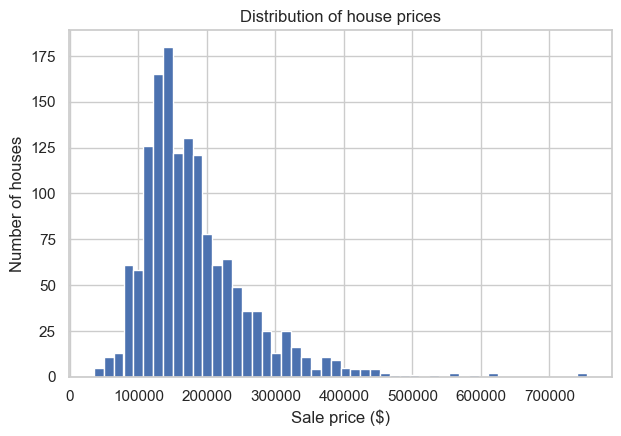

In [ ]:
data["SalePrice"].hist(bins=50)
plt.xlabel("Sale price ($)")
plt.ylabel("Number of houses")
plt.title("Distribution of house prices")
plt.show()

<div dir="rtl">

توزیع **چوله به راست** است: بیشتر خانه‌ها بین ۱۰۰ تا ۲۵۰ هزار دلار هستند و تعداد کمی خانهٔ خیلی گران داریم.

### 🔍 کارآگاه داده: چند خانهٔ عجیب
منطقی است که هرچه خانه بزرگ‌تر باشد، گران‌تر باشد. بیایید رابطهٔ متراژ و قیمت را ببینیم:

</div>

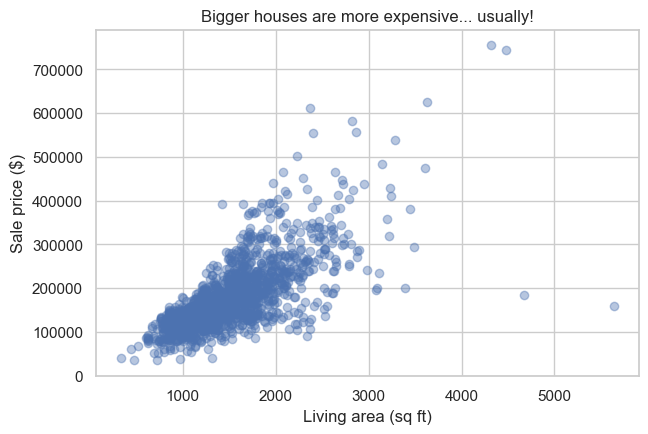

In [ ]:
plt.scatter(data["GrLivArea"], data["SalePrice"], alpha=0.4)
plt.xlabel("Living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.title("Bigger houses are more expensive... usually!")
plt.show()

<div dir="rtl">

به گوشهٔ پایین-راست نمودار نگاه کنید: دو خانهٔ **خیلی بزرگ** با قیمت **خیلی ارزان**!
خود سازندهٔ این دیتاست (Dean De Cock) توصیه کرده خانه‌های بالای ۴۰۰۰ فوت مربع حذف شوند، چون برخی از آن‌ها فروش‌های غیرعادی بوده‌اند (مثلاً فروش بخشی از ملک) و قیمت واقعی بازار را نشان نمی‌دهند.

</div>

In [ ]:
print(data[data["GrLivArea"] > 4000])

data = data[data["GrLivArea"] <= 4000]
print("Rows left:", len(data))

      OverallQual  GrLivArea  TotalBsmtSF  GarageArea  YearBuilt  LotFrontage  \
523            10       4676         3138         884       2007        130.0   
691            10       4316         2444         832       1994        104.0   
1182           10       4476         2396         813       1996        160.0   
1298           10       5642         6110        1418       2008        313.0   

      MasVnrArea  FullBath  OverallCond  Fireplaces  SalePrice  
523        762.0         3            5           1     184750  
691       1170.0         3            6           2     755000  
1182         0.0         3            5           2     745000  
1298       796.0         2            5           3     160000  
Rows left: 1456


<div dir="rtl">

حالا ببینیم کدام ویژگی‌ها بیشترین **همبستگی** را با قیمت دارند. `data.corr()` ماتریس همبستگی را حساب می‌کند و `sns.heatmap` آن را رنگی نشان می‌دهد:

</div>

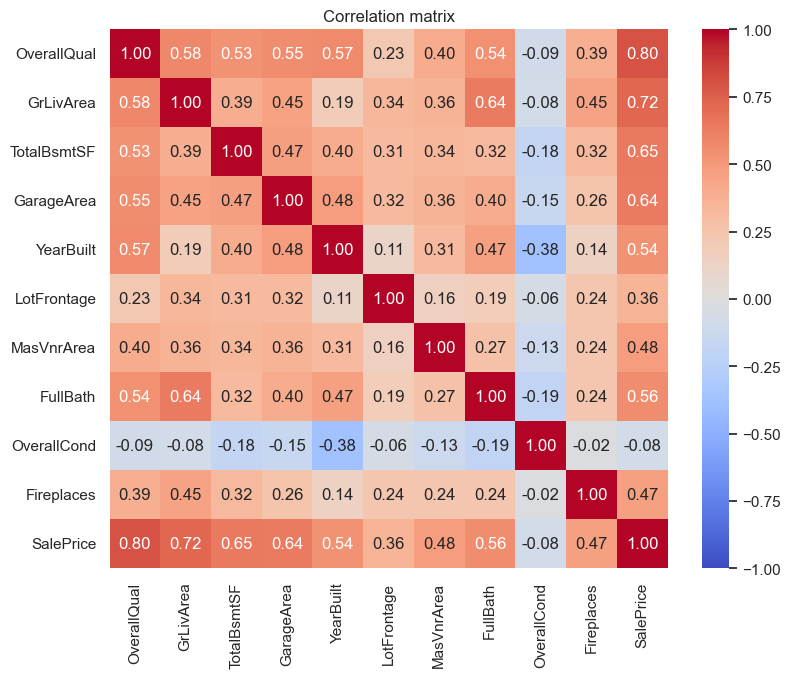

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

<div dir="rtl">

ردیف آخر (`SalePrice`) را نگاه کنید: **کیفیت کلی** (`OverallQual`) و **متراژ** (`GrLivArea`) قوی‌ترین رابطه را با قیمت دارند.

یک نکتهٔ جالب دیگر: قیمت با بالا رفتن کیفیت **خطی** زیاد نمی‌شود — هرچه کیفیت بالاتر می‌رود، قیمت **سریع‌تر** بالا می‌رود. این را در بخش ۵ به یاد داشته باشید!

</div>

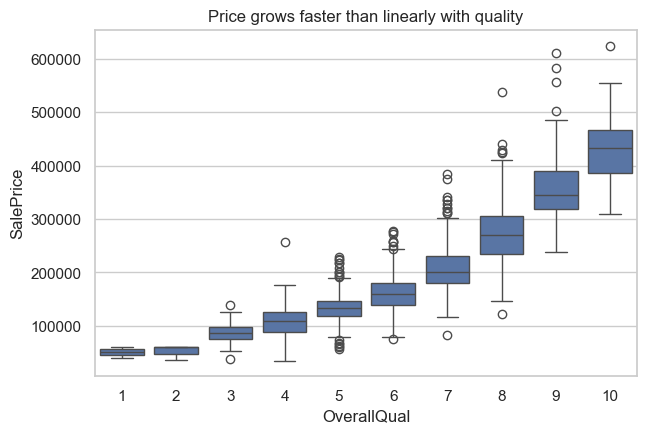

In [ ]:
sns.boxplot(data=data, x="OverallQual", y="SalePrice")
plt.title("Price grows faster than linearly with quality")
plt.show()

<div dir="rtl">

## ۲. داده‌های گمشده (Missing Values)

در خروجی `info()` دیدیم که بعضی ستون‌ها خانهٔ خالی دارند. بیایید دقیق بشماریم:

</div>

In [ ]:
data.isna().sum()

OverallQual      0
GrLivArea        0
TotalBsmtSF      0
GarageArea       0
YearBuilt        0
LotFrontage    259
MasVnrArea       8
FullBath         0
OverallCond      0
Fireplaces       0
SalePrice        0
dtype: int64

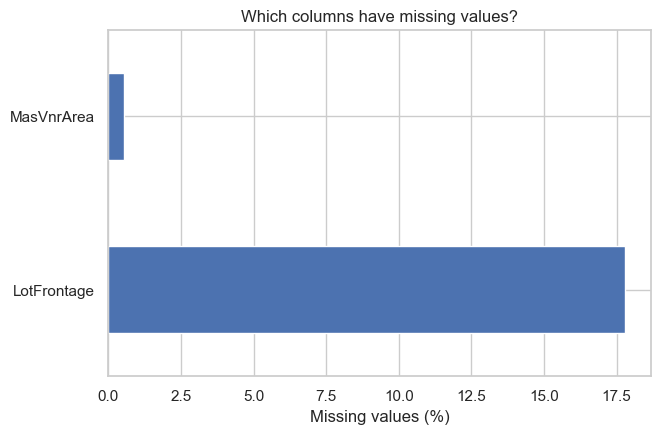

In [ ]:
missing_percent = data.isna().mean() * 100
missing_percent[missing_percent > 0].plot.barh()
plt.xlabel("Missing values (%)")
plt.title("Which columns have missing values?")
plt.show()

<div dir="rtl">

حدود **۱۸٪** از مقدارهای `LotFrontage` خالی است. دو راه داریم:

۱. **حذف ردیف‌های ناقص** با `dropna()`. ساده است، ولی ببینید چقدر داده از دست می‌دهیم:

</div>

In [ ]:
print("All rows:              ", len(data))
print("Rows without any NaN:  ", len(data.dropna()))

All rows:               1456
Rows without any NaN:   1191


<div dir="rtl">

بیش از ۲۵۰ خانه را دور بریزیم؟ حیف است!

💡 **همیشه بپرسید داده چرا گم شده؟** در دیتاست اصلی ستونی به اسم `GarageYrBlt` (سال ساخت پارکینگ) هم هست که ۸۱ جای خالی دارد. آن جاهای خالی مال خانه‌هایی است که اصلاً **پارکینگ ندارند**! آن‌جا «گمشده» یعنی «وجود ندارد»، و پر کردنش با میانه بی‌معنی است. ما این ستون را عمداً انتخاب نکردیم (اطلاعاتش هم تقریباً همان `YearBuilt` است). ولی جاهای خالی `LotFrontage` واقعاً «نامعلوم»‌اند، پس پر کردنشان منطقی است.

۲. **پر کردن جاهای خالی (Imputation)**: مثلاً هر جای خالی را با **میانه** (median) همان ستون پر کنیم. میانه را به میانگین ترجیح می‌دهیم چون به داده‌های پرت حساس نیست.

⚠️ **اما یک سؤال مهم:** میانه را از روی **کدام** داده حساب کنیم؟ اگر از کل داده حساب کنیم، اطلاعات دادهٔ test به مدل «نشت» می‌کند (**data leakage**).
پس اول باید داده را تقسیم کنیم.

</div>

<div dir="rtl">

## ۳. تقسیم داده: Train / Validation / Test

یک تشبیه آشنا برای ما ایرانی‌ها 😄

| بخش | تشبیه | کاربرد |
|---|---|---|
| **Train** (۶۰٪) | کتاب تست | مدل از روی آن یاد می‌گیرد |
| **Validation** (۲۰٪) | آزمون آزمایشی | با آن بین مدل‌ها و تنظیمات مختلف انتخاب می‌کنیم |
| **Test** (۲۰٪) | کنکور اصلی | فقط **یک بار** در انتها، برای گزارش عملکرد واقعی |

اگر مدام با سؤال‌های کنکور اصلی تمرین کنیم، نمرهٔ کنکورمان دیگر نشان‌دهندهٔ سطح واقعی‌مان نیست!

`train_test_split` داده را فقط به دو بخش تقسیم می‌کند، پس آن را **دو بار** صدا می‌زنیم.
قیمت را هم به **هزار دلار** تبدیل می‌کنیم تا اعداد خطا راحت‌تر خوانده شوند.

</div>

In [ ]:
from sklearn.model_selection import train_test_split

X = data[features]
y = data["SalePrice"] / 1000          # price in thousands of dollars

# step 1: keep 20% aside as the final test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# step 2: split the remaining 80% into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Train:      (873, 10)
Validation: (291, 10)
Test:       (292, 10)


<div dir="rtl">

چرا `test_size=0.25` در خط دوم؟ چون ۲۵٪ از ۸۰٪ باقی‌مانده می‌شود ۲۰٪ کل داده.
`random_state=42` هم باعث می‌شود هر بار دقیقاً همین تقسیم تکرار شود.

</div>

<div dir="rtl">

## ۴. پیش‌پردازش: Imputation و Scaling

### ۴.۱ پر کردن جاهای خالی با `SimpleImputer`

تقریباً همهٔ ابزارهای `scikit-learn` یک الگوی ثابت دارند:

- `fit` ← از روی داده **یاد بگیر** (این‌جا: میانهٔ هر ستون را حساب کن)
- `transform` ← چیزی که یاد گرفتی را **اعمال کن** (این‌جا: جاهای خالی را پر کن)

قانون طلایی: **`fit` فقط روی train، و `transform` روی هر سه بخش.**

</div>

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)

# the medians the imputer learned from the training set
pd.Series(imputer.statistics_, index=features)

OverallQual       6.0
GrLivArea      1458.0
TotalBsmtSF    1001.0
GarageArea      484.0
YearBuilt      1974.0
LotFrontage      70.0
MasVnrArea        0.0
FullBath          2.0
OverallCond       5.0
Fireplaces        1.0
dtype: float64

In [ ]:
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=features, index=X_train.index)
X_val_imp   = pd.DataFrame(imputer.transform(X_val),   columns=features, index=X_val.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=features, index=X_test.index)

print("Missing values left in train:", X_train_imp.isna().sum().sum())

Missing values left in train: 0


<div dir="rtl">

خروجی `transform` یک آرایهٔ `numpy` است؛ ما آن را دوباره به `DataFrame` تبدیل کردیم تا نام ستون‌ها حفظ شود.

Imputation مجانی نیست! ببینیم با توزیع `LotFrontage` چه کرد:

</div>

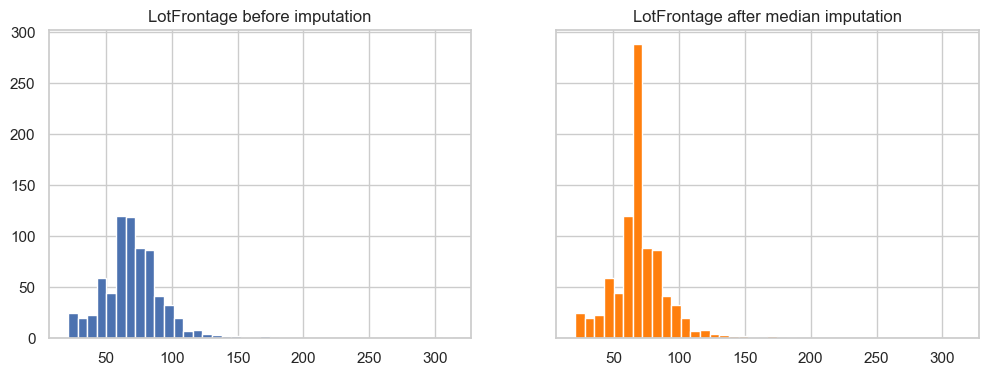

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(X_train["LotFrontage"].dropna(), bins=40)
axes[0].set_title("LotFrontage before imputation")

axes[1].hist(X_train_imp["LotFrontage"], bins=40, color="tab:orange")
axes[1].set_title("LotFrontage after median imputation")

plt.show()

<div dir="rtl">

یک **ستون بلند** درست روی میانه ظاهر شد! همهٔ خانه‌های ناقص حالا یک عدد یکسان دارند.
برای این مسئله قابل قبول است، ولی همیشه بعد از imputation توزیع داده را چک کنید.

### ۴.۲ هم‌مقیاس کردن با `StandardScaler`

به بازهٔ ویژگی‌ها نگاه کنید: متراژ در حد **هزارها** است ولی تعداد شومینه بین **۰ تا ۳**!

</div>

In [ ]:
X_train_imp.describe().loc[["mean", "std", "min", "max"]].round(1)

,OverallQual,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt,LotFrontage,MasVnrArea,FullBath,OverallCond,Fireplaces
mean,6.1,1501.7,1060.7,477.6,1972.5,70.2,102.2,1.6,5.6,0.6
std,1.4,491.4,419.4,215.7,29.4,21.9,170.5,0.6,1.1,0.6
min,1.0,438.0,0.0,0.0,1872.0,21.0,0.0,0.0,1.0,0.0
max,10.0,3627.0,3200.0,1390.0,2010.0,313.0,1378.0,3.0,9.0,3.0


<div dir="rtl">

چرا این مشکل است؟

- **Gradient Descent** روی ویژگی‌های غیرهم‌مقیاس خیلی کند و زیگزاگی همگرا می‌شود.
- **Regularization** (بخش ۷) به همهٔ وزن‌ها یکسان جریمه می‌دهد؛ اگر مقیاس‌ها متفاوت باشند، این جریمه منصفانه نیست.
- وزن‌های مدل **قابل مقایسه** نمی‌شوند.

`StandardScaler` هر ستون را این‌طور تبدیل می‌کند (میانگین ۰ و انحراف معیار ۱):

$$z = \frac{x - \mu}{\sigma}$$

باز هم همان قانون طلایی: $\mu$ و $\sigma$ را فقط از train یاد می‌گیریم.

</div>

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train_imp)

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=features, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val_imp),   columns=features, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),  columns=features, index=X_test.index)

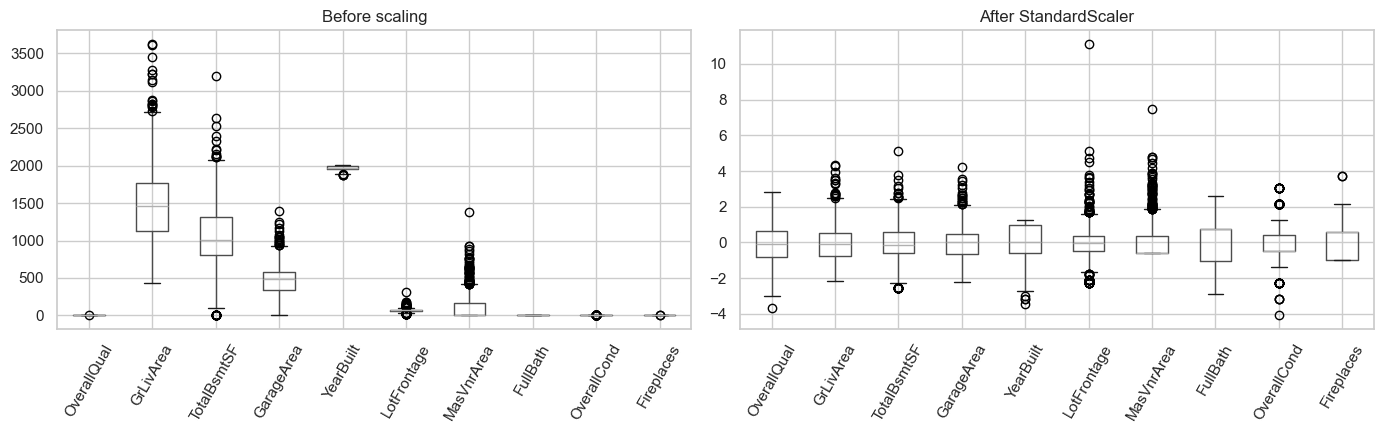

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

X_train_imp.boxplot(ax=axes[0], rot=60)
axes[0].set_title("Before scaling")

X_train_scaled.boxplot(ax=axes[1], rot=60)
axes[1].set_title("After StandardScaler")

plt.tight_layout()
plt.show()

<div dir="rtl">

قبل از scaling فقط `GrLivArea` و `TotalBsmtSF` دیده می‌شدند؛ حالا همه در یک بازه هستند. ✅

</div>

<div dir="rtl">

## ۵. رگرسیون خطی

### ۵.۱ با یک ویژگی: متراژ

ساده‌ترین مدل ممکن یک خط است:

$$\hat{y} = w_0 + w_1 \cdot \text{GrLivArea}$$

`LinearRegression` بهترین $w_0$ و $w_1$ را طوری پیدا می‌کند که **مجموع مربعات خطا** کمینه شود.
این‌جا از دادهٔ **scale نشده** استفاده می‌کنیم تا وزن‌ها واحد واقعی داشته باشند.

</div>

In [ ]:
from sklearn.linear_model import LinearRegression

simple_model = LinearRegression()
simple_model.fit(X_train_imp[["GrLivArea"]], y_train)

print("w0 (intercept):", round(simple_model.intercept_, 2))
print("w1 (slope):    ", round(simple_model.coef_[0], 4))

w0 (intercept): 2.53
w1 (slope):     0.1193


<div dir="rtl">

**تفسیر:** شیب حدود ۰٫۱۲ یعنی هر **یک فوت مربع** متراژ بیشتر، به‌طور میانگین حدود **۱۲۰ دلار** به قیمت اضافه می‌کند (یادتان هست قیمت به هزار دلار است). یعنی هر **متر مربع** حدود ۱۳۰۰ دلار!

بیایید خط را روی داده ببینیم:

</div>

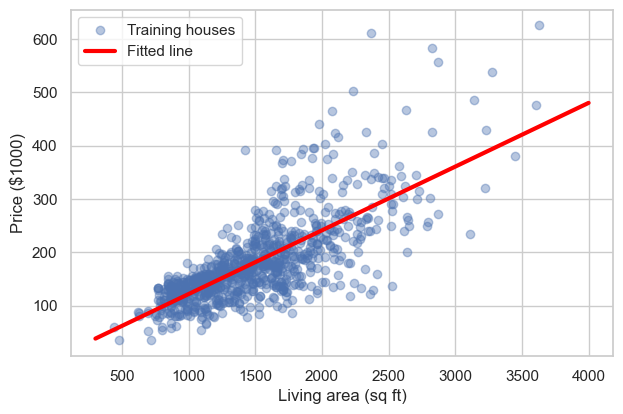

In [ ]:
x_line = pd.DataFrame({"GrLivArea": np.linspace(300, 4000, 100)})
y_line = simple_model.predict(x_line)

plt.scatter(X_train_imp["GrLivArea"], y_train, alpha=0.4, label="Training houses")
plt.plot(x_line["GrLivArea"], y_line, color="red", linewidth=3, label="Fitted line")
plt.xlabel("Living area (sq ft)")
plt.ylabel("Price ($1000)")
plt.legend()
plt.show()

<div dir="rtl">

🎯 **یک پیش‌بینی:** یک خانهٔ ۲۰۰۰ فوت مربعی (حدود ۱۸۵ متر مربع) چند می‌ارزد؟

</div>

In [ ]:
new_house = pd.DataFrame({"GrLivArea": [2000]})
simple_model.predict(new_house)

array([241.20613983])

<div dir="rtl">

### ۵.۲ با همهٔ ویژگی‌ها

حالا همهٔ ۱۰ ویژگی را به مدل می‌دهیم:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_{10} x_{10}$$

</div>

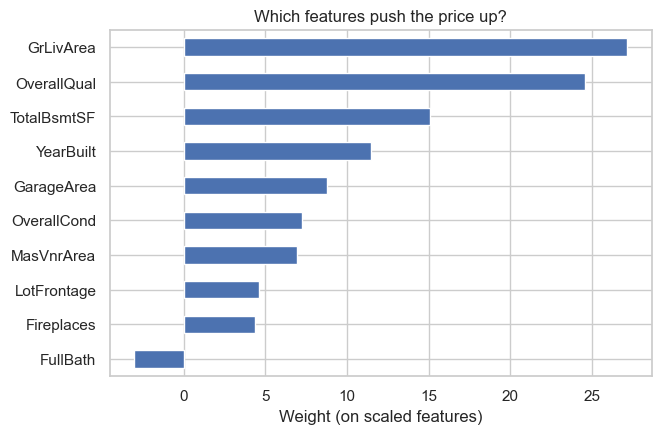

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

weights = pd.Series(lin_reg.coef_, index=features).sort_values()
weights.plot.barh()
plt.xlabel("Weight (on scaled features)")
plt.title("Which features push the price up?")
plt.show()

<div dir="rtl">

چون ویژگی‌ها هم‌مقیاس شده‌اند، **اندازهٔ وزن‌ها قابل مقایسه است**: متراژ و کیفیت مهم‌ترین عوامل هستند. 🏆

🤔 **سؤال برای بحث در کلاس:** چرا وزن `FullBath` (تعداد حمام) **منفی** شده؟ یعنی حمام بیشتر خانه را ارزان‌تر می‌کند؟!
(راهنمایی: وزن هر ویژگی اثر آن را **با ثابت ماندن بقیهٔ ویژگی‌ها** نشان می‌دهد. اگر متراژ ثابت بماند و حمام اضافه شود، از فضای اتاق‌ها چه کم می‌شود؟ به همبستگی `FullBath` و `GrLivArea` در heatmap هم نگاه کنید.)

### ۵.۳ مدل چقدر خوب است؟

سه معیار رایج:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad \text{RMSE} = \sqrt{\text{MSE}} \qquad R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

- **RMSE** هم‌واحد با قیمت است (این‌جا هزار دلار)، پس راحت تفسیر می‌شود.
- **$R^2$** می‌گوید مدل چه کسری از تغییرات قیمت را توضیح می‌دهد (۱ یعنی کامل).

</div>

In [ ]:
from sklearn.metrics import root_mean_squared_error, r2_score

y_train_pred = lin_reg.predict(X_train_scaled)
y_val_pred = lin_reg.predict(X_val_scaled)

print("Train      RMSE:", round(root_mean_squared_error(y_train, y_train_pred), 1), " R2:", round(r2_score(y_train, y_train_pred), 3))
print("Validation RMSE:", round(root_mean_squared_error(y_val, y_val_pred), 1), " R2:", round(r2_score(y_val, y_val_pred), 3))

Train      RMSE: 32.5  R2: 0.833
Validation RMSE: 30.9  R2: 0.817


<div dir="rtl">

یعنی پیش‌بینی‌های ما به‌طور معمول حدود **۳۰ هزار دلار** خطا دارند و مدل بیش از ۸۰٪ تغییرات قیمت را توضیح می‌دهد. برای یک خط، بد نیست! 👏

نمودار **پیش‌بینی در برابر واقعیت**: اگر مدل بی‌نقص بود، همهٔ نقطه‌ها روی خط قرمز می‌افتادند.

</div>

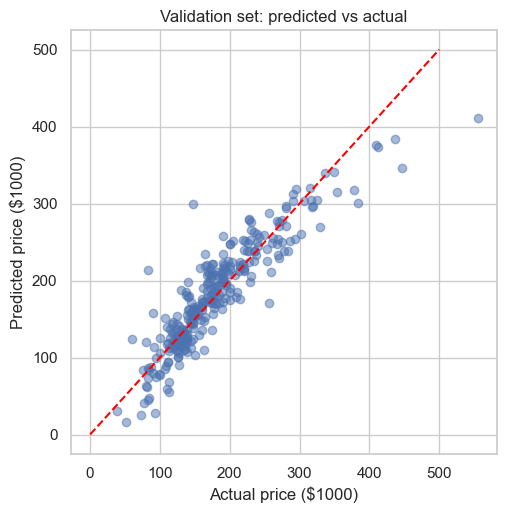

In [ ]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_val, y_val_pred, alpha=0.5)
plt.plot([0, 500], [0, 500], color="red", linestyle="--")
plt.xlabel("Actual price ($1000)")
plt.ylabel("Predicted price ($1000)")
plt.title("Validation set: predicted vs actual")
plt.show()

<div dir="rtl">

### ۵.۴ باقی‌مانده‌ها چه می‌گویند؟

**باقی‌مانده** (residual) یعنی $y - \hat{y}$. اگر مدل همهٔ الگوهای داده را گرفته باشد، باقی‌مانده‌ها باید **بی‌نظم** حول صفر پخش شوند.

</div>

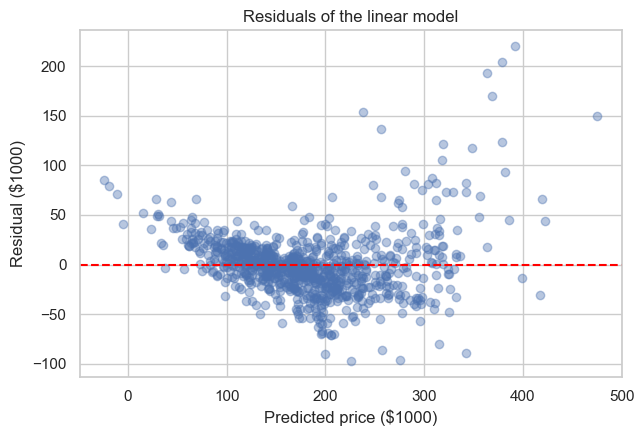

In [ ]:
residuals = y_train - y_train_pred

plt.scatter(y_train_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price ($1000)")
plt.ylabel("Residual ($1000)")
plt.title("Residuals of the linear model")
plt.show()

<div dir="rtl">

یک **الگوی خمیده (U شکل)** می‌بینید؟ برای خانه‌های ارزان و گران، باقی‌مانده‌ها بیشتر مثبت‌اند و برای خانه‌های متوسط بیشتر منفی.
(در سمت چپ نمودار حتی یک پیش‌بینی **منفی** هم هست! قیمت منفی برای یک خانه؟ 😅)
یعنی مدل ما یک **انحنا** در داده را نمی‌بیند. وقت آن است که مدل را منعطف‌تر کنیم! 🚀

</div>

<div dir="rtl">

## ۶. رگرسیون چندجمله‌ای (Polynomial Regression)

### ۶.۱ ایده: ساختن ویژگی‌های جدید

ترفند ساده است: به جای عوض کردن مدل، **ویژگی‌های جدید** می‌سازیم ($x^2$، $x^3$، $x_1 x_2$ و ...) و همان رگرسیون خطی را روی آن‌ها اجرا می‌کنیم:

$$\hat{y} = w_0 + w_1 x + w_2 x^2 + w_3 x^3$$

مدل نسبت به **وزن‌ها** هنوز خطی است، پس `LinearRegression` همچنان کار می‌کند!

ابزار `PolynomialFeatures` این ویژگی‌ها را خودکار می‌سازد. روی یک مثال کوچک ببینیم:

</div>

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

toy = pd.DataFrame({"a": [1, 2, 3], "b": [10, 20, 30]})

poly = PolynomialFeatures(degree=2, include_bias=False)
toy_poly = poly.fit_transform(toy)

pd.DataFrame(toy_poly, columns=poly.get_feature_names_out())

,a,b,a^2,a b,b^2
0,1.0,10.0,1.0,10.0,100.0
1,2.0,20.0,4.0,40.0,400.0
2,3.0,30.0,9.0,90.0,900.0


<div dir="rtl">

از ۲ ستون، ۵ ستون ساخته شد: خود ویژگی‌ها، مربع‌هایشان و حاصل‌ضربشان. (`include_bias=False` یعنی ستون ثابت ۱ را نساز، چون `LinearRegression` خودش $w_0$ دارد.)

🤔 **حدس بزنید:** با ۱۰ ویژگی و درجهٔ ۳، چند ستون ساخته می‌شود؟ (جواب در بخش ۶.۴!)

### ۶.۲ زنجیر کردن مراحل با `Pipeline`

تا این‌جا هر مرحله را دستی برای train و validation و test اجرا کردیم. با اضافه شدن مرحلهٔ جدید، این کار هم خسته‌کننده است و هم احتمال اشتباه را بالا می‌برد.
`make_pipeline` مراحل را پشت سر هم می‌چیند و همه را با یک `fit` و یک `predict` اجرا می‌کند:

<pre dir="ltr">SimpleImputer  →  PolynomialFeatures  →  StandardScaler  →  LinearRegression</pre>

(بعد از ساخت ویژگی‌های چندجمله‌ای scale می‌کنیم، چون $x^3$ مقیاس کاملاً متفاوتی با $x$ دارد.)

</div>

In [ ]:
from sklearn.pipeline import make_pipeline

poly2_model = make_pipeline(
    SimpleImputer(strategy="median"),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression(),
)

poly2_model.fit(X_train, y_train)          # raw data in, the pipeline does everything!
poly2_model

,steps,"[('simpleimputer', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,degree,2


In [ ]:
y_val_pred_poly2 = poly2_model.predict(X_val)

print("Linear     validation RMSE:", round(root_mean_squared_error(y_val, y_val_pred), 1))
print("Degree 2   validation RMSE:", round(root_mean_squared_error(y_val, y_val_pred_poly2), 1))

Linear     validation RMSE: 30.9
Degree 2   validation RMSE: 26.7


<div dir="rtl">

خطا حدود **۴ هزار دلار** کمتر شد! 🎉

### ۶.۳ ببینیم با یک ویژگی چه اتفاقی می‌افتد

برای این‌که بتوانیم منحنی‌ها را **ببینیم**، فقط از یک ویژگی (`YearBuilt`) و یک نمونهٔ **کوچک** از ۲۰ خانه استفاده می‌کنیم.
سه مدل با درجه‌های ۱، ۳ و ۱۲ می‌سازیم.

⚠️ یک نکتهٔ عددی: $2000^{12} \approx 4 \times 10^{39}$! با چنین اعداد غول‌آسایی محاسبات کامپیوتر دقتش را از دست می‌دهد. برای همین این‌جا یک `StandardScaler` هم **قبل** از `PolynomialFeatures` می‌گذاریم تا سال‌ها اول به اعداد کوچک حول صفر تبدیل شوند.

</div>

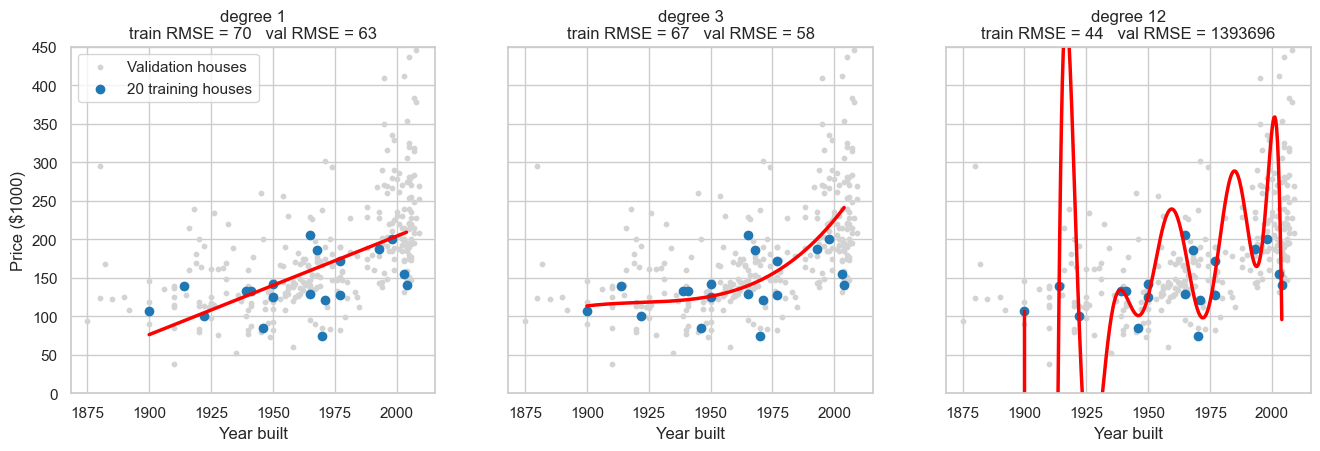

In [ ]:
small = X_train[["YearBuilt"]].sample(20, random_state=0)
y_small = y_train[small.index]

x_plot = pd.DataFrame({"YearBuilt": np.linspace(small["YearBuilt"].min(), small["YearBuilt"].max(), 300)})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, degree in zip(axes, [1, 3, 12]):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(small, y_small)

    train_rmse = root_mean_squared_error(y_small, model.predict(small))
    val_rmse = root_mean_squared_error(y_val, model.predict(X_val[["YearBuilt"]]))

    ax.scatter(X_val["YearBuilt"], y_val, color="lightgray", s=10, label="Validation houses")
    ax.scatter(small["YearBuilt"], y_small, color="tab:blue", label="20 training houses")
    ax.plot(x_plot["YearBuilt"], model.predict(x_plot), color="red", linewidth=2.5)
    ax.set_title(f"degree {degree}\ntrain RMSE = {train_rmse:.0f}   val RMSE = {val_rmse:.0f}")
    ax.set_xlabel("Year built")
    ax.set_ylim(0, 450)

axes[0].set_ylabel("Price ($1000)")
axes[0].legend(loc="upper left")
plt.show()

<div dir="rtl">

- **درجهٔ ۱ (Underfitting):** خط ساده‌تر از واقعیت است — **bias** بالا.
- **درجهٔ ۳:** منحنی ملایم و منطقی؛ خانه‌های نوساز گران‌ترند.
- **درجهٔ ۱۲ (Overfitting):** منحنی دیوانه‌وار پیچ‌وتاب می‌خورد تا از تک‌تک نقطه‌های آبی رد شود. خطای train کم شده ولی خطای validation **منفجر** شده! — **variance** بالا.

پس «پیچیده‌تر» همیشه «بهتر» نیست. چطور بهترین درجه را پیدا کنیم؟

</div>

<div dir="rtl">

## ۷. پیدا کردن بهترین درجه

### ۷.۱ با مجموعهٔ Validation

یک حلقهٔ ساده: برای هر درجه مدل را روی train می‌سازیم و خطای train و validation را ثبت می‌کنیم.

</div>

In [ ]:
degrees = [1, 2, 3, 4]
train_errors = []
val_errors = []

for degree in degrees:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    model.fit(X_train, y_train)
    train_errors.append(root_mean_squared_error(y_train, model.predict(X_train)))
    val_errors.append(root_mean_squared_error(y_val, model.predict(X_val)))
    # model[i] is step i of the pipeline: model[1] = PolynomialFeatures, model[-1] = the regression model
    print(f"degree {degree}: {model[1].n_output_features_:5d} features")

pd.DataFrame({"degree": degrees, "train RMSE": train_errors, "validation RMSE": val_errors}).round(1)

degree 1:    10 features
degree 2:    65 features
degree 3:   285 features


degree 4:  1000 features


,degree,train RMSE,validation RMSE
0,1,32.5,30.9
1,2,24.1,26.7
2,3,17.1,41.2
3,4,0.6,8870.4


<div dir="rtl">

جواب سؤال بخش ۶.۱: با درجهٔ ۳، **۲۸۵ ویژگی** ساخته می‌شود و با درجهٔ ۴، **۱۰۰۰ ویژگی** — بیشتر از تعداد خانه‌های train!

</div>

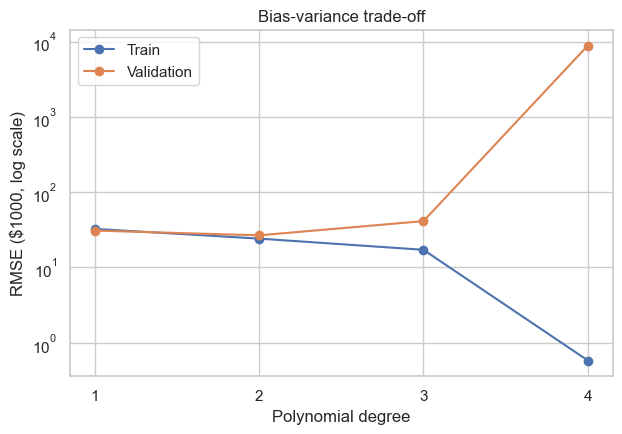

In [ ]:
plt.plot(degrees, train_errors, "o-", label="Train")
plt.plot(degrees, val_errors, "o-", label="Validation")
plt.yscale("log")                      # degree 4 is so bad we need a log scale
plt.xticks(degrees)
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE ($1000, log scale)")
plt.title("Bias-variance trade-off")
plt.legend()
plt.show()

<div dir="rtl">

این همان نمودار معروف **bias–variance trade-off** است:

- خطای **train** با افزایش درجه همیشه کم می‌شود (در درجهٔ ۴ تقریباً صفر!).
- خطای **validation** اول کم و بعد زیاد می‌شود.
- **بهترین درجه = ۲**، جایی که خطای validation کمینه است.

### ۷.۲ با Cross-Validation

یک مشکل: نتیجهٔ بالا فقط به **یک** تقسیم تصادفی وابسته است. شاید شانسی بوده!
در **K-Fold Cross-Validation**، دادهٔ train+validation را به $K$ قسمت تقسیم می‌کنیم؛ هر بار یک قسمت validation می‌شود و بقیه train. در نهایت میانگین $K$ خطا را گزارش می‌کنیم:

<pre dir="ltr">
Fold 1:  [ VAL ][train][train][train][train]
Fold 2:  [train][ VAL ][train][train][train]
Fold 3:  [train][train][ VAL ][train][train]
Fold 4:  [train][train][train][ VAL ][train]
Fold 5:  [train][train][train][train][ VAL ]
</pre>

دادهٔ test همچنان دست‌نخورده می‌ماند. `cross_val_score` همهٔ این کار را در یک خط انجام می‌دهد:

</div>

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(poly2_model, X_temp, y_temp, cv=cv, scoring="neg_root_mean_squared_error")

print("RMSE on each fold:", (-scores).round(1))
print("Mean RMSE:        ", round(-scores.mean(), 1))

RMSE on each fold: [27.4 25.3 24.8 31.4 28.7]
Mean RMSE:         27.5


<div dir="rtl">

**چرا علامت منفی؟** `scikit-learn` همیشه فرض می‌کند «عدد بزرگ‌تر = بهتر»، پس خطا را منفی برمی‌گرداند. ما دوباره مثبتش می‌کنیم.

**نکتهٔ زیبا:** چون از Pipeline استفاده کردیم، imputer و scaler در هر fold **فقط روی بخش train همان fold** فیت می‌شوند. هیچ نشتی رخ نمی‌دهد! 🔒

حالا همین کار را برای همهٔ درجه‌ها با `validation_curve` انجام می‌دهیم.
اسم پارامتر به شکل `stepname__paramname` است (با **دو** خط زیر)؛ `make_pipeline` اسم هر مرحله را از اسم کلاسش با حروف کوچک می‌سازد.

</div>

In [ ]:
from sklearn.model_selection import validation_curve

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    LinearRegression(),
)

train_scores, val_scores = validation_curve(
    pipeline, X_temp, y_temp,
    param_name="polynomialfeatures__degree",
    param_range=[1, 2, 3],
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

cv_results = pd.DataFrame({
    "degree": [1, 2, 3],
    "train RMSE": -train_scores.mean(axis=1),
    "CV RMSE": -val_scores.mean(axis=1),
})
cv_results.round(1)

,degree,train RMSE,CV RMSE
0,1,31.9,32.4
1,2,24.1,27.5
2,3,17.8,54.3


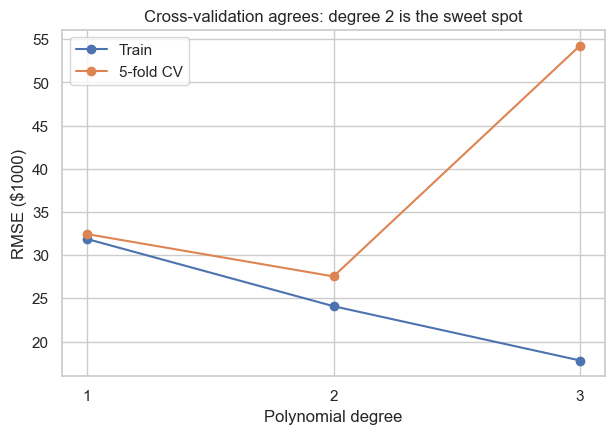

In [ ]:
plt.plot(cv_results["degree"], cv_results["train RMSE"], "o-", label="Train")
plt.plot(cv_results["degree"], cv_results["CV RMSE"], "o-", label="5-fold CV")
plt.xticks([1, 2, 3])
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE ($1000)")
plt.title("Cross-validation agrees: degree 2 is the sweet spot")
plt.legend()
plt.show()

<div dir="rtl">

Cross-validation هم تأیید می‌کند: **درجهٔ ۲ بهترین است** و درجهٔ ۳ به‌شدت overfit می‌شود.

</div>

<div dir="rtl">

## ۸. Regularization: رام کردن مدل‌های پیچیده

### ۸.۱ ایده

درجهٔ ۳ خیلی منعطف بود و overfit شد. به جای کم کردن درجه، می‌توانیم انعطاف را نگه داریم ولی به مدل بگوییم: **«وزن‌های بزرگ ممنوع!»**

اول ببینیم وزن‌ها در مدل overfit واقعاً چقدر بزرگ می‌شوند:

</div>

In [ ]:
for degree in [1, 2, 3]:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    model.fit(X_train, y_train)
    print(f"degree {degree}: largest |weight| = {np.abs(model[-1].coef_).max():8.1f}")

degree 1: largest |weight| =     27.2
degree 2: largest |weight| =    633.8
degree 3: largest |weight| = 124713.6


<div dir="rtl">

وزن‌های غول‌آسا = منحنی‌های پرپیچ‌وتاب. پس یک **جریمه** به تابع هزینه اضافه می‌کنیم:

$$\textbf{Ridge (L2):}\quad J(\mathbf{w}) = \text{MSE} + \lambda \sum_{j} w_j^2$$

$$\textbf{Lasso (L1):}\quad J(\mathbf{w}) = \text{MSE} + \lambda \sum_{j} |w_j|$$

هرچه $\lambda$ بزرگ‌تر باشد، مدل ساده‌تر می‌شود. در `scikit-learn` به $\lambda$ می‌گویند **`alpha`**.

### ۸.۲ Ridge

مدل درجهٔ ۳ را با مقدارهای مختلف `alpha` امتحان می‌کنیم:

</div>

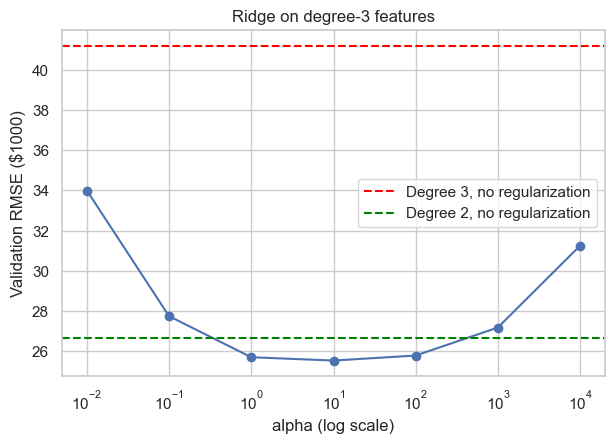

In [ ]:
from sklearn.linear_model import Ridge

alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]
ridge_val_errors = []

for alpha in alphas:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha),
    )
    model.fit(X_train, y_train)
    ridge_val_errors.append(root_mean_squared_error(y_val, model.predict(X_val)))

plt.semilogx(alphas, ridge_val_errors, "o-")
plt.axhline(val_errors[2], color="red", linestyle="--", label="Degree 3, no regularization")
plt.axhline(val_errors[1], color="green", linestyle="--", label="Degree 2, no regularization")
plt.xlabel("alpha (log scale)")
plt.ylabel("Validation RMSE ($1000)")
plt.title("Ridge on degree-3 features")
plt.legend()
plt.show()

In [ ]:
best_ridge_alpha = alphas[np.argmin(ridge_val_errors)]
print("Best alpha:", best_ridge_alpha)
print("Validation RMSE:", round(min(ridge_val_errors), 1))

Best alpha: 10
Validation RMSE: 25.5


<div dir="rtl">

- `alpha` خیلی کوچک ← تقریباً همان مدل overfit (خط قرمز).
- `alpha` خیلی بزرگ ← مدل بیش از حد ساده می‌شود (underfit).
- در وسط، Ridge مدل درجهٔ ۳ را **حتی از بهترین مدل درجهٔ ۲ هم بهتر** می‌کند! 🎉

**Ridge دقیقاً با وزن‌ها چه می‌کند؟** برای این‌که نمودار خوانا باشد، این را روی ۱۰ ویژگی اصلی (بدون چندجمله‌ای) و دادهٔ scale شدهٔ بخش ۴ نشان می‌دهیم:

</div>

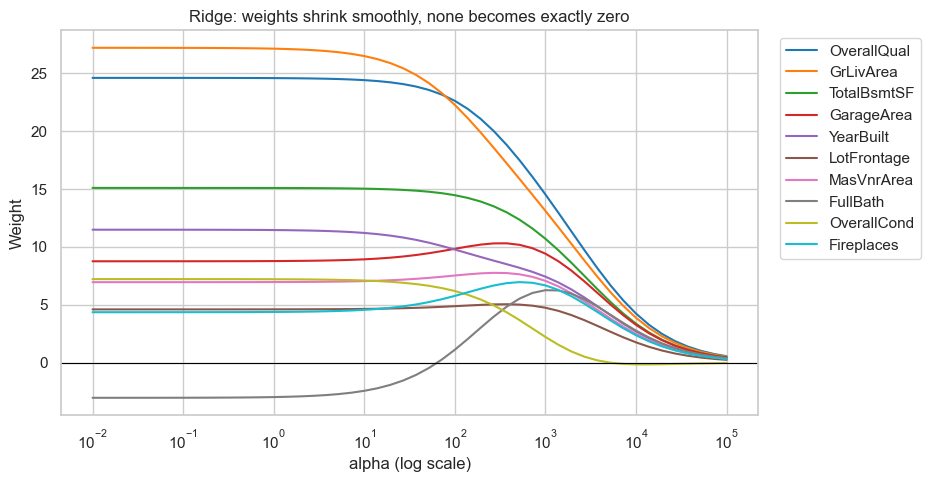

In [ ]:
path_alphas = np.logspace(-2, 5, 50)
ridge_weights = []

for alpha in path_alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    ridge_weights.append(model.coef_)

ridge_weights = pd.DataFrame(ridge_weights, index=path_alphas, columns=features)

ridge_weights.plot(logx=True, figsize=(9, 5), colormap="tab10")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("alpha (log scale)")
plt.ylabel("Weight")
plt.title("Ridge: weights shrink smoothly, none becomes exactly zero")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

<div dir="rtl">

با بزرگ شدن `alpha`، **اندازهٔ کلی** بردار وزن‌ها آرام‌آرام کوچک می‌شود و در نهایت همه به سمت صفر می‌روند، ولی هیچ‌کدام **دقیقاً** صفر نمی‌شوند.

به `FullBath` دقت کنید: وزنش اول **منفی** است، بعد **مثبت** می‌شود! `GarageArea` و `Fireplaces` هم قبل از کوچک شدن کمی بزرگ‌تر می‌شوند. دلیلش این است که ویژگی‌ها با هم **همبسته‌اند**: وقتی Ridge وزن متراژ را کم می‌کند، بخشی از نقش آن به ویژگی‌های همبسته (مثل تعداد حمام) منتقل می‌شود.

### ۸.۳ Lasso

همان آزمایش را با Lasso تکرار می‌کنیم. این بار تعداد وزن‌های **غیرصفر** را هم می‌شماریم.
(`max_iter` را بالا می‌بریم چون Lasso با یک الگوریتم تکراری حل می‌شود و با ۲۸۵ ویژگی به تکرار بیشتری نیاز دارد.)

</div>

In [ ]:
from sklearn.linear_model import Lasso

lasso_alphas = [0.03, 0.1, 0.3, 1, 3, 10]
lasso_val_errors = []
lasso_nonzero = []

for alpha in lasso_alphas:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=100_000),
    )
    model.fit(X_train, y_train)
    lasso_val_errors.append(root_mean_squared_error(y_val, model.predict(X_val)))
    lasso_nonzero.append(np.sum(model[-1].coef_ != 0))

pd.DataFrame({"alpha": lasso_alphas, "validation RMSE": np.round(lasso_val_errors, 1), "non-zero weights (of 285)": lasso_nonzero})

,alpha,validation RMSE,non-zero weights (of 285)
0,0.03,26.0,99
1,0.10,25.5,64
2,0.30,25.3,32
3,1.00,25.2,17
4,3.00,25.5,16
5,10.00,27.9,9


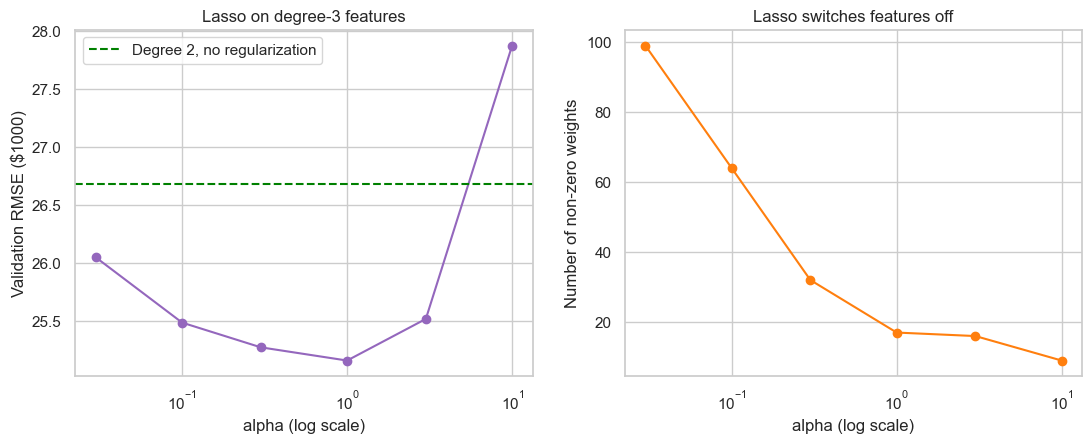

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(lasso_alphas, lasso_val_errors, "o-", color="tab:purple")
axes[0].axhline(val_errors[1], color="green", linestyle="--", label="Degree 2, no regularization")
axes[0].set_xlabel("alpha (log scale)")
axes[0].set_ylabel("Validation RMSE ($1000)")
axes[0].set_title("Lasso on degree-3 features")
axes[0].legend()

axes[1].semilogx(lasso_alphas, lasso_nonzero, "o-", color="tab:orange")
axes[1].set_xlabel("alpha (log scale)")
axes[1].set_ylabel("Number of non-zero weights")
axes[1].set_title("Lasso switches features off")

plt.show()

<div dir="rtl">

فوق‌العاده است! 🤯 Lasso با نگه داشتن فقط **بخش کوچکی** از ۲۸۵ ویژگی، به خطایی در حد بهترین مدل‌ها می‌رسد.
یعنی Lasso علاوه بر regularization، **انتخاب ویژگی (feature selection)** هم انجام می‌دهد.

مسیر وزن‌ها برای Lasso روی ۱۰ ویژگی اصلی:

</div>

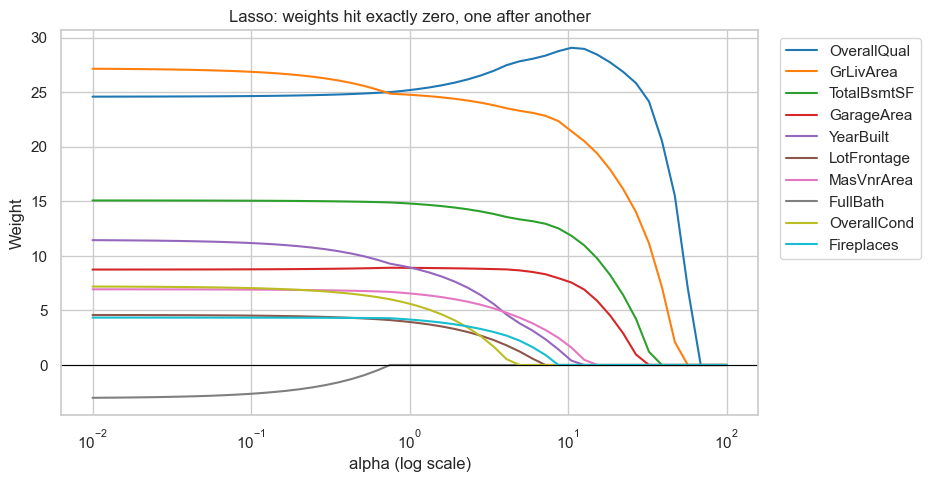

In [ ]:
path_alphas = np.logspace(-2, 2, 50)
lasso_weights = []

for alpha in path_alphas:
    model = Lasso(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    lasso_weights.append(model.coef_)

lasso_weights = pd.DataFrame(lasso_weights, index=path_alphas, columns=features)

lasso_weights.plot(logx=True, figsize=(9, 5), colormap="tab10")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("alpha (log scale)")
plt.ylabel("Weight")
plt.title("Lasso: weights hit exactly zero, one after another")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

<div dir="rtl">

تفاوت را با Ridge مقایسه کنید: در Lasso وزن‌ها یکی‌یکی **دقیقاً به صفر می‌رسند** و آن‌جا می‌مانند. آخرین ویژگی‌ای که زنده می‌ماند، مهم‌ترین ویژگی است. حدس می‌زنید کدام باشد؟
(وزن `OverallQual` حتی قبل از افتادن کمی **بالا** می‌رود؛ چون نقش ویژگی‌های همبسته‌ای را که حذف شده‌اند به عهده می‌گیرد.)

حالا ببینیم بهترین مدل Lasso از بین ۲۸۵ ویژگی، کدام‌ها را نگه داشته:

</div>

alpha = 1: Lasso kept 17 of 285 features


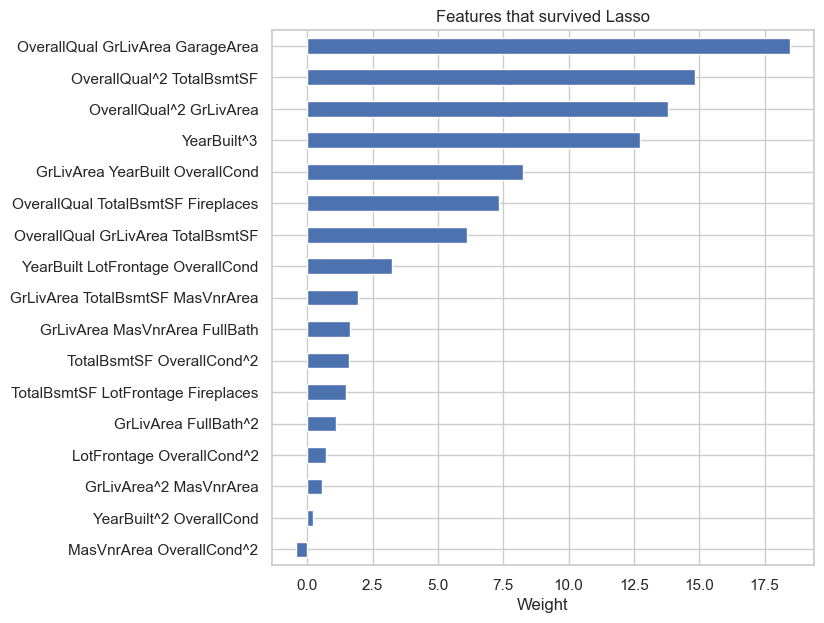

In [ ]:
best_lasso_alpha = lasso_alphas[np.argmin(lasso_val_errors)]

best_lasso = make_pipeline(
    SimpleImputer(strategy="median"),
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Lasso(alpha=best_lasso_alpha, max_iter=100_000),
)
best_lasso.fit(X_train, y_train)

feature_names = best_lasso[1].get_feature_names_out(features)
lasso_coef = pd.Series(best_lasso[-1].coef_, index=feature_names)
kept = lasso_coef[lasso_coef != 0].sort_values()

print(f"alpha = {best_lasso_alpha}: Lasso kept {len(kept)} of {len(lasso_coef)} features")
kept.plot.barh(figsize=(7, 0.35 * len(kept) + 1))
plt.xlabel("Weight")
plt.title("Features that survived Lasso")
plt.show()

<div dir="rtl">

ویژگی‌های باقی‌مانده معنی‌دار هستند. مثلاً:
- `OverallQual^2 GrLivArea` (مربع کیفیت × متراژ): یک متر اضافه در یک خانهٔ **باکیفیت** خیلی بیشتر می‌ارزد تا در یک خانهٔ کم‌کیفیت!
- `YearBuilt^3`: خانه‌های نوساز با شیب **تندتری** گران می‌شوند (همان منحنی بخش ۶.۳).

از ۱۰ ویژگی اصلی تقریباً هیچ‌کدام به‌تنهایی باقی نمانده‌اند؛ Lasso ترکیب‌های آن‌ها را مفیدتر دیده است.

### ۸.۴ (اختیاری) جستجوی خودکار با `GridSearchCV`

در عمل معمولاً درجه و `alpha` را **با هم** و با cross-validation جستجو می‌کنیم. `GridSearchCV` همهٔ ترکیب‌ها را امتحان می‌کند:

</div>

In [ ]:
from sklearn.model_selection import GridSearchCV

ridge_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    Ridge(),
)

param_grid = {
    "polynomialfeatures__degree": [1, 2, 3],
    "ridge__alpha": [0.1, 1, 10, 100, 1000],
}

search = GridSearchCV(ridge_pipeline, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
search.fit(X_temp, y_temp)

print("Best parameters:", search.best_params_)
print("Best CV RMSE:   ", round(-search.best_score_, 1))

Best parameters: {'polynomialfeatures__degree': 3, 'ridge__alpha': 10}
Best CV RMSE:    27.1


<div dir="rtl">

`GridSearchCV` با ۵-fold cross-validation به همان جوابی رسید که ما دستی با validation پیدا کردیم: **درجهٔ ۳ + Ridge با `alpha=10`**. ✅

</div>

<div dir="rtl">

## ۹. تصویر کردن مدل‌ها

### ۹.۱ Regularization منحنی دیوانه را آرام می‌کند

همان ۲۰ خانهٔ بخش ۶.۳ و همان مدل درجهٔ ۱۲ را به یاد دارید؟ این بار Ridge با `alpha`های مختلف را امتحان می‌کنیم:

</div>

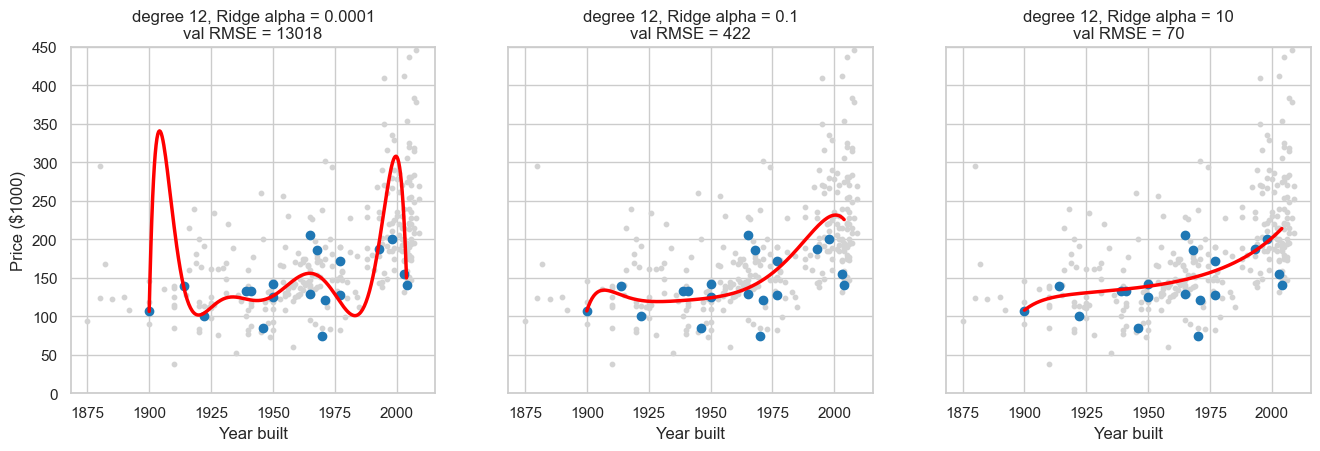

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, alpha in zip(axes, [0.0001, 0.1, 10]):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(12, include_bias=False), StandardScaler(), Ridge(alpha=alpha))
    model.fit(small, y_small)
    val_rmse = root_mean_squared_error(y_val, model.predict(X_val[["YearBuilt"]]))

    ax.scatter(X_val["YearBuilt"], y_val, color="lightgray", s=10)
    ax.scatter(small["YearBuilt"], y_small, color="tab:blue")
    ax.plot(x_plot["YearBuilt"], model.predict(x_plot), color="red", linewidth=2.5)
    ax.set_title(f"degree 12, Ridge alpha = {alpha}\nval RMSE = {val_rmse:.0f}")
    ax.set_xlabel("Year built")
    ax.set_ylim(0, 450)

axes[0].set_ylabel("Price ($1000)")
plt.show()

<div dir="rtl">

با بزرگ‌تر شدن `alpha`، منحنی درجهٔ ۱۲ کم‌کم صاف و منطقی می‌شود — **بدون این‌که درجه را عوض کرده باشیم!** خطای validation هم از بیش از ۱۰ هزار به حدود ۷۰ می‌رسد.

### ۹.۲ سطح پیش‌بینی (معادل «مرز تصمیم» در رگرسیون)

در classification «مرز تصمیم» را رسم می‌کنیم. در رگرسیون، معادلش **سطح پیش‌بینی** است: برای هر ترکیب از دو ویژگی، مدل چه قیمتی پیش‌بینی می‌کند؟
هر **خط تراز** (contour) نشان‌دهندهٔ خانه‌هایی است که قیمت پیش‌بینی‌شدهٔ **یکسانی** دارند.

دو مدل را فقط با دو ویژگی مهم (متراژ و کیفیت) مقایسه می‌کنیم:

</div>

In [ ]:
two_features = ["GrLivArea", "OverallQual"]

linear_2d = make_pipeline(StandardScaler(), LinearRegression())
poly_2d = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=1))

linear_2d.fit(X_train[two_features], y_train)
poly_2d.fit(X_train[two_features], y_train)

# a grid of 100 x 100 imaginary houses
area_grid, quality_grid = np.meshgrid(np.linspace(300, 4000, 100), np.linspace(1, 10, 100))
grid = pd.DataFrame({"GrLivArea": area_grid.ravel(), "OverallQual": quality_grid.ravel()})

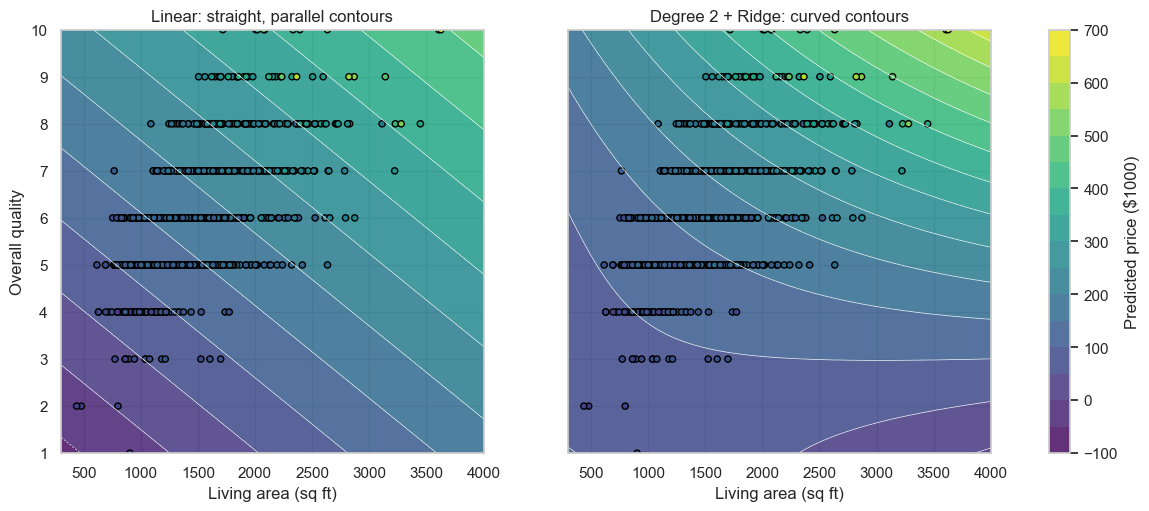

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
levels = np.arange(-100, 701, 50)

for ax, model, title in zip(axes, [linear_2d, poly_2d], ["Linear: straight, parallel contours", "Degree 2 + Ridge: curved contours"]):
    price_grid = model.predict(grid).reshape(area_grid.shape)
    contour = ax.contourf(area_grid, quality_grid, price_grid, levels=levels, cmap="viridis", alpha=0.85)
    ax.contour(area_grid, quality_grid, price_grid, levels=levels, colors="white", linewidths=0.5)
    ax.scatter(X_train["GrLivArea"], X_train["OverallQual"], c=y_train, cmap="viridis",
               vmin=-100, vmax=700, edgecolor="black", s=20)
    ax.set_title(title)
    ax.set_xlabel("Living area (sq ft)")

axes[0].set_ylabel("Overall quality")
fig.colorbar(contour, ax=axes, label="Predicted price ($1000)")
plt.show()

<div dir="rtl">

- در مدل **خطی**، خطوط تراز **صاف و موازی**‌اند: اثر متراژ برای همهٔ کیفیت‌ها یکسان است. گوشهٔ پایین-چپ را ببینید: مدل خطی برای خانه‌های کوچک و بی‌کیفیت قیمت **منفی** پیش‌بینی می‌کند!
- در مدل **درجهٔ ۲**، خطوط تراز **خمیده**‌اند و در بالا-راست به هم نزدیک‌تر می‌شوند: یعنی برای خانه‌های باکیفیت، هر فوت مربع اضافه گران‌تر است. این دقیقاً همان اثر `OverallQual GrLivArea` است که Lasso هم پیدایش کرد!

اگر رنگ نقطه‌ها (قیمت واقعی) با رنگ پس‌زمینه (قیمت پیش‌بینی‌شده) هم‌خوان باشد، یعنی مدل خوب کار می‌کند.

</div>

<div dir="rtl">

## ۱۰. لحظهٔ حقیقت: ارزیابی نهایی روی Test 🏁

بالاخره وقت «کنکور اصلی» است. همهٔ مدل‌های نهایی را روی train می‌سازیم و **فقط یک بار** روی test ارزیابی می‌کنیم:

</div>

In [ ]:
final_models = {
    "Linear (degree 1)": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    "Polynomial (degree 2)": make_pipeline(SimpleImputer(strategy="median"), PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "Polynomial (degree 3)": make_pipeline(SimpleImputer(strategy="median"), PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression()),
    "Ridge (degree 3)": make_pipeline(SimpleImputer(strategy="median"), PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=best_ridge_alpha)),
    "Lasso (degree 3)": make_pipeline(SimpleImputer(strategy="median"), PolynomialFeatures(3, include_bias=False), StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=100_000)),
}

rows = []
for name, model in final_models.items():
    model.fit(X_train, y_train)
    rows.append({
        "model": name,
        "train RMSE": root_mean_squared_error(y_train, model.predict(X_train)),
        "validation RMSE": root_mean_squared_error(y_val, model.predict(X_val)),
        "test RMSE": root_mean_squared_error(y_test, model.predict(X_test)),
        "test R2": r2_score(y_test, model.predict(X_test)),
    })

leaderboard = pd.DataFrame(rows).set_index("model").round(3)
leaderboard

,train RMSE,validation RMSE,test RMSE,test R2
model,,,,
Linear (degree 1),32.470,30.856,29.070,0.839
Polynomial (degree 2),24.130,26.676,25.813,0.873
Polynomial (degree 3),17.142,41.204,47.940,0.562
Ridge (degree 3),23.560,25.531,24.874,0.882
Lasso (degree 3),26.189,25.156,24.146,0.889


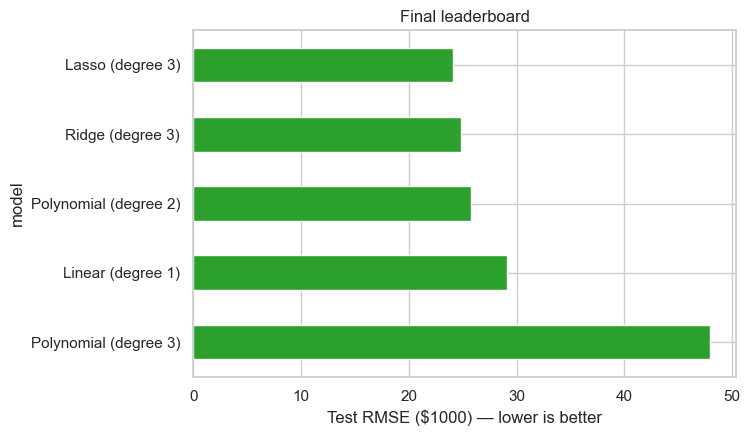

In [ ]:
leaderboard["test RMSE"].sort_values(ascending=False).plot.barh(color="tab:green")
plt.xlabel("Test RMSE ($1000) — lower is better")
plt.title("Final leaderboard")
plt.show()

<div dir="rtl">

نتیجه‌ها:

- مدل **خطی** ساده نقطهٔ شروع خوبی بود.
- **درجهٔ ۲** با گرفتن انحنای داده، خطا را کم کرد.
- **درجهٔ ۳ بدون regularization** شکست خورد (overfitting کلاسیک: خطای train کم، خطای test زیاد).
- **Ridge و Lasso** همان مدل درجهٔ ۳ را نجات دادند و بهترین نتیجه‌ها را گرفتند. 🏆

### بهترین مدل در عمل

بیایید چند خانهٔ test را که مدل هرگز ندیده، با پیش‌بینی بهترین مدل مقایسه کنیم:

</div>

In [ ]:
best_name = leaderboard["test RMSE"].idxmin()
best_model = final_models[best_name]
print("Best model:", best_name)

sample_houses = X_test.head(8).copy()
sample_houses["actual price ($1000)"] = y_test.head(8).round(0)
sample_houses["predicted price ($1000)"] = best_model.predict(X_test.head(8)).round(0)
sample_houses[["OverallQual", "GrLivArea", "YearBuilt", "actual price ($1000)", "predicted price ($1000)"]]

Best model: Lasso (degree 3)


,OverallQual,GrLivArea,YearBuilt,actual price ($1000),predicted price ($1000)
497,7,1820,1925,184.0,161.0
1264,6,1337,1998,181.0,168.0
411,5,1056,1955,145.0,127.0
1048,5,1771,1960,115.0,119.0
1035,4,845,1957,84.0,83.0
614,4,630,1972,76.0,94.0
218,7,1954,1939,312.0,219.0
1185,5,1221,1924,105.0,117.0


In [ ]:
errors = (y_test - best_model.predict(X_test)).abs()
percent_errors = errors / y_test * 100

print(f"Median error:         ${errors.median() * 1000:,.0f}")
print(f"Median percent error: {percent_errors.median():.1f}%")

Median error:         $12,237
Median percent error: 7.4%


<div dir="rtl">

یعنی برای **نیمی از خانه‌های test**، خطای پیش‌بینی ما کمتر از **حدود ۱۲ هزار دلار** (کمتر از ۸٪ قیمت خانه) است. 🎯
آن هم فقط با ۱۰ ویژگی ساده و یک مدل خطی!

</div>

<div dir="rtl">

## ۱۱. جمع‌بندی

در این نوت‌بوک یک مسئلهٔ واقعی را از صفر تا صد حل کردیم:

| مرحله | درسی که گرفتیم |
|---|---|
| آشنایی با داده | قبل از مدل‌سازی، داده را **نگاه کن** (داده‌های پرت، توزیع‌ها، همبستگی‌ها) |
| تقسیم داده | train برای یادگیری، validation برای انتخاب، test فقط **یک بار** در انتها |
| Imputation و Scaling | `fit` فقط روی train؛ `transform` روی همه |
| رگرسیون خطی | ساده، سریع و قابل تفسیر — همیشه با آن شروع کن |
| رگرسیون چندجمله‌ای | با ساختن ویژگی‌های جدید، مدل خطی منحنی یاد می‌گیرد |
| Bias–Variance | مدل ساده ← underfit؛ مدل خیلی پیچیده ← overfit |
| Cross-Validation | انتخاب مطمئن‌تر از یک تقسیم شانسی |
| Ridge و Lasso | انعطاف را نگه دار، وزن‌های بزرگ را جریمه کن؛ Lasso ویژگی هم انتخاب می‌کند |
| Pipeline | کد تمیزتر و بدون data leakage |

## ✍️ تمرین برای شما

۱. **ویژگی جدید:** ستون `LotArea` (مساحت زمین) را به `features` اضافه کنید و کل نوت‌بوک را دوباره اجرا کنید. چه اتفاقی برای مدل درجهٔ ۳ می‌افتد؟ چرا؟ (راهنمایی: `describe()` این ستون را نگاه کنید.)

۲. **استراتژی دیگر:** در `SimpleImputer` به جای `"median"` از `"mean"` استفاده کنید. نتیجه تغییر می‌کند؟

۳. **تبدیل هدف:** به جای `SalePrice` مدل را روی `np.log(SalePrice)` آموزش دهید (یادتان هست توزیع قیمت چوله بود؟). برای مقایسهٔ منصفانه، پیش‌بینی‌ها را با `np.exp` برگردانید.

۴. **تعداد foldها:** در cross-validation به جای ۵ از ۱۰ fold استفاده کنید. آیا بهترین درجه تغییر می‌کند؟

۵. **چالش 🌶️:** ستون `Neighborhood` (نام محله) یک ویژگی **متنی** است. با `OneHotEncoder` آن را به مدل اضافه کنید. (راهنمایی: `ColumnTransformer` را جستجو کنید.)

</div>